# TP 4 — Assembler et entraîner le mini-Transformer

Objectif : réutiliser les notions des TP1, TP2 et TP3 pour construire un modèle de langage, entraîner ses poids sur Tiny Shakespear, mesurer les pertes entraînement/validation et générer du texte.

Pipeline: préparation → tête d'attention → multi-têtes → bloc résiduel → embeddings → logits et loss → génération → évaluation et entraînement → expériences.

Les cellules sont autonomes : exécuter le notebook dans l'ordre. Les réponses aux questions d'interprétation sont intégrées après chaque étape.

Deux modes : MODE_RAPIDE = True permet un premier test court (recommandé pour vérifier le code) ; repasser à False et réexécuter tout le notebook pour les 5 000 itérations du sujet. Activer un GPU dans Exécution → Modifier le type d'exécution → T4 GPU* si possible.

## Étape 0 — Importer les bibliothèques, préparer Tiny Shakespeare

In [1]:
import math
from pathlib import Path
from urllib.request import urlretrieve

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch : 2.11.0+cu130
GPU disponible : True


In [2]:
# Même corpus et même tokenisation caractère par caractère que le TP1.
source = Path("input.txt")
if not source.is_file():
    url = ("https://raw.githubusercontent.com/karpathy/"
           "char-rnn/master/data/tinyshakespeare/input.txt")
    urlretrieve(url, source)

text = source.read_text(encoding="utf-8")
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

assert decode(encode(text[:40])) == text[:40]
assert len(train_data) > 0 and len(val_data) > 0
print(f"Corpus : {len(text):,} caractères | vocabulaire : {vocab_size} tokens")
print(f"Train : {len(train_data):,} | Validation : {len(val_data):,}")
print("Extrait :", repr(text[:100]))

Corpus : 1,115,394 caractères | vocabulaire : 65 tokens
Train : 1,003,854 | Validation : 111,540
Extrait : 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou'


### Paramètres du TP4
Le modèle utilise le même découpage chronologique 90 % entraînement / 10 % validation que le TP1. block_size définit la longueur maximale de contexte. Les hyperparamètres complets sont ceux du sujet, le mode rapide change seulement le temps d'exécution pour le diagnostic.

In [3]:
MODE_RAPIDE = True  # Pour le rendu final : False, puis « Tout exécuter ».

batch_size = 16
block_size = 32
max_iters = 80 if MODE_RAPIDE else 5000
eval_interval = 20 if MODE_RAPIDE else 100
learning_rate = 1e-3
device = "cuda" if torch.cuda.is_available() else "cpu"
eval_iters = 10 if MODE_RAPIDE else 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
assert len(val_data) > block_size + 1
print("Device :", device, "| Dimension par tête :", n_embd // n_head)
print("Tokens par batch :", batch_size * block_size)
print("Itérations :", max_iters, "| Mini-batchs par mesure :", eval_iters)

Device : cuda | Dimension par tête : 16
Tokens par batch : 512
Itérations : 80 | Mini-batchs par mesure : 10


In [4]:
def get_batch(split, *, context_size=None, batch_size_override=None):
    """Échantillonne B séquences de T caractères et leurs cibles décalées."""
    source = train_data if split == "train" else val_data
    length = block_size if context_size is None else context_size
    size = batch_size if batch_size_override is None else batch_size_override
    starts = torch.randint(len(source) - length, (size,))
    x = torch.stack([source[i:i + length] for i in starts]).to(device)
    y = torch.stack([source[i + 1:i + length + 1] for i in starts]).to(device)
    return x, y

xb, yb = get_batch("train")
assert xb.shape == yb.shape == (batch_size, block_size)
assert torch.equal(xb[:, 1:], yb[:, :-1])
print("x, y :", xb.shape, yb.shape)

x, y : torch.Size([16, 32]) torch.Size([16, 32])


**Questions d'interprétation de l'Étape 0**

1. Dimension d'une tête :  64/4=16

2. Taille du batch :B*T = 16*32 = 512 positions de prédiction (mais seulement 16 séquences).

3. Sur CPU : réduire d'abord max_iters et eval_iters pour vérifier rapidement le code, puis éventuellement batch_size. Conserver la configuration complète pour une expérience comparable à celle demandée.

## Étape 1 — Implémenter une tête d’auto-attention causale (page 22)

La query Q du token courant est comparée aux keys K pour obtenir des scores. Le masque interdit de regarder les tokens futurs. La distribution normalisée pondère les values V :



In [5]:
class Head(nn.Module):
    """Une tête d'attention causale : (B,T,n_embd) → (B,T,d_h)."""
    def __init__(self, head_size, context_size=block_size, drop=dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(context_size, context_size)))
        self.dropout = nn.Dropout(drop)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)       # (B,T,d_h)
        wei = q @ k.transpose(-2, -1)          # (B,T,T)
        wei = wei * k.size(-1)**-0.5            # 1 / sqrt(d_h)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)            # Somme de chaque ligne = 1
        wei = self.dropout(wei)
        v = self.value(x)                       # (B,T,d_h)
        return wei @ v                          # (B,T,d_h)

### Vérifications — formes, masque et causalité
Le sujet demande de vérifier les dimensions et que **le futur ne contribue jamais aux poids**. Nous contrôlons cela numériquement, sans entraîner de modèle.

In [6]:
head_test = Head(head_size=16, context_size=block_size)
head_test.eval()  # Dropout désactivé pour le test de causalité.
x_test = torch.randn(2, 8, n_embd)

with torch.no_grad():
    q, k = head_test.query(x_test), head_test.key(x_test)
    scores = (q @ k.transpose(-2, -1)) * k.size(-1)**-0.5
    scores = scores.masked_fill(head_test.tril[:8, :8] == 0, float("-inf"))
    wei_test = F.softmax(scores, dim=-1)
    sortie_test = head_test(x_test)

assert q.shape == k.shape == (2, 8, 16)
assert wei_test.shape == (2, 8, 8)
assert sortie_test.shape == (2, 8, 16)
assert torch.allclose(wei_test.sum(-1), torch.ones(2, 8), atol=1e-6)
assert torch.count_nonzero(torch.triu(wei_test, diagonal=1)) == 0

# Modifier uniquement les tokens futurs ne doit PAS modifier les premières sorties.
x_modifie = x_test.clone()
x_modifie[:, 5:] += 100
assert torch.allclose(head_test(x_test)[:, :5], head_test(x_modifie)[:, :5], atol=1e-5)
print("OK : formes, somme des lignes, masque causal et absence de fuite du futur.")
print("Matrice d'attention du premier exemple :\n", wei_test[0].round(decimals=3))

OK : formes, somme des lignes, masque causal et absence de fuite du futur.
Matrice d'attention du premier exemple :
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4540, 0.5460, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3930, 0.1370, 0.4690, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2690, 0.2110, 0.2500, 0.2700, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2130, 0.1270, 0.1450, 0.2020, 0.3140, 0.0000, 0.0000, 0.0000],
        [0.2030, 0.2120, 0.1080, 0.2050, 0.1110, 0.1610, 0.0000, 0.0000],
        [0.1450, 0.2100, 0.0700, 0.0650, 0.1690, 0.0680, 0.2730, 0.0000],
        [0.1120, 0.0950, 0.1840, 0.1050, 0.1430, 0.0840, 0.1550, 0.1210]])


**Questions d'interprétation — Étape 1**

- Pourquoi k.size(-1) plutôt que C ? Le produit scalaire compare des vecteurs de dimension 16, pas les embeddings d'entrée C=64. On divise donc par $\sqrt{16}$.
- Pourquoi tril[:T, :T] ? Le modèle peut traiter des contextes plus courts que block_size, notamment au début de la génération.
- Formes : $q,k,v\in\mathbb{R}^{B\times T\times d_h}$ ; poids $\in\mathbb{R}^{B\times T\times T}$ ; sortie $\in\mathbb{R}^{B\times T\times d_h}$.

## Étape 2 — Combiner plusieurs têtes

In [7]:
class MultiHeadAttention(nn.Module):
    """Concatène les têtes, puis projette vers n_embd dimensions."""
    def __init__(self, num_heads, head_size, context_size=block_size, drop=dropout):
        super().__init__()
        assert num_heads * head_size == n_embd
        self.heads = nn.ModuleList([
            Head(head_size, context_size=context_size, drop=drop)
            for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(drop)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

multi_test = MultiHeadAttention(num_heads=4, head_size=16)
y_test = multi_test(torch.randn(2, 8, n_embd))
assert y_test.shape == (2, 8, 64)
print("4 têtes × 16 dimensions →", y_test.shape)

4 têtes × 16 dimensions → torch.Size([2, 8, 64])


**Questions d'interprétation — Étape 2**

- Pourquoi dim=-1 ? Pour ajouter côte à côte les features produites par les quatre têtes, sans mélanger les positions temporelles : $4\times16=64$.
- Pourquoi $n_{embd}$ divisible par $n_{head}$ ? Pour répartir les 64 dimensions en têtes de taille égale (ici 16 chacune) et retrouver 64 dimensions après concaténation.
-  À quoi sert la projection ? À combiner linéairement les informations issues des différentes têtes.

## Étape 3 — Feed-forward, LayerNorm et résidus

In [8]:
class FeedForward(nn.Module):
    """MLP appliqué indépendamment à chaque token : C → 4C → C."""
    def __init__(self, dim, drop=dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.ReLU(),
            nn.Linear(4 * dim, dim),
            nn.Dropout(drop),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """Bloc Transformer pré-norm : attention + résiduel, MLP + résiduel."""
    def __init__(self, dim, num_heads, context_size=block_size, drop=dropout):
        super().__init__()
        assert dim == n_embd and dim % num_heads == 0
        head_size = dim // num_heads
        self.sa = MultiHeadAttention(num_heads, head_size, context_size, drop)
        self.ffwd = FeedForward(dim, drop)
        self.ln1 = nn.LayerNorm(dim)
        self.ln2 = nn.LayerNorm(dim)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

bloc_test = Block(n_embd, n_head)
assert bloc_test(torch.randn(2, 8, n_embd)).shape == (2, 8, n_embd)
print("Bloc résiduel : (2,8,64) → (2,8,64), OK")

Bloc résiduel : (2,8,64) → (2,8,64), OK


**Questions d'interprétation — Étape 3**

1. **Ordre :** `LayerNorm` → sous-couche (attention ou MLP) → addition résiduelle. C'est une architecture **pré-norm**.
2. **Communication :** l'attention permet à un token de prendre des informations dans les positions précédentes.
3. **Calcul individuel :** le MLP transforme les features **à chaque position**, sans accéder à un autre token.
4. **Résiduel :** l'addition `x + delta` conserve une voie de circulation du signal et facilite l'optimisation. Les dimensions restent $(B,T,64)$.

## Étapes 4, 5 et 6 — Modèle complet, forward, loss et génération

**Rôle des composants :** `token_embedding_table` encode le caractère, `position_embedding_table` sa position, les blocs mélangent le contexte et transforment les tokens, puis `lm_head` calcule un score pour chaque caractère possible.

In [9]:
class BigramLanguageModel(nn.Module):
    """Mini-Transformer causal à caractères (nom historique du TP1)."""
    def __init__(self, context_size=block_size, num_heads=n_head, n_blocks=n_layer, drop=dropout):
        super().__init__()
        self.context_size = context_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(context_size, n_embd)
        self.blocks = nn.Sequential(*[
            Block(n_embd, num_heads, context_size, drop)
            for _ in range(n_blocks)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.context_size:
            raise ValueError("Contexte plus long que context_size")
        tok_emb = self.token_embedding_table(idx)       # (B,T,64)
        positions = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(positions)  # (T,64)
        x = tok_emb + pos_emb                          # Broadcasting vers (B,T,64)
        x = self.blocks(x)                             # (B,T,64)
        x = self.ln_f(x)
        logits = self.lm_head(x)                       # (B,T,vocab_size)
        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B * T, vocab_size)
            targets = targets.reshape(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        """Ajoute des caractères en respectant le contexte limité du modèle."""
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]                  # Dernier pas de temps seulement
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

### Vérifier les dimensions et la loss (avant tout entraînement)

On vérifie aussi qu'une génération sans cible conserve les logits de forme `(B,T,vocab_size)`, alors qu'avec cibles la loss utilise les `(B×T)` positions.

In [10]:
model = BigramLanguageModel().to(device)
print(f"Paramètres entraînables : {sum(p.numel() for p in model.parameters()):,}")

xb, yb = get_batch("train")
logits_generation, loss_none = model(xb)
logits_train, loss_train = model(xb, yb)
assert logits_generation.shape == (batch_size, block_size, vocab_size)
assert logits_train.shape == (batch_size * block_size, vocab_size)
assert loss_none is None and loss_train.ndim == 0
assert torch.isfinite(loss_train)
print("Logits génération :", logits_generation.shape)
print("Logits entraînement :", logits_train.shape)
print("Loss initiale :", round(loss_train.item(), 4))

Paramètres entraînables : 209,729
Logits génération : torch.Size([16, 32, 65])
Logits entraînement : torch.Size([512, 65])
Loss initiale : 4.3816


**Questions d'interprétation — Étapes 4–6**

- **Tailles des matrices :** embedding de tokens $(V,64)$, embedding de positions $(32,64)$, `lm_head` : projection $(64,V)$ (plus un biais de taille $V$).
- **Pourquoi `lm_head` séparée ?** Contrairement au bigramme du TP1, les caractères sont d'abord encodés dans **64 dimensions** et contextualisés ; on convertit ensuite la représentation de chaque position en **$V$ logits**.
- **Broadcasting :** $(B,T,64)+(T,64)$ additionne le même vecteur de position à tous les exemples du batch.
- **Loss :** la cross-entropy compare les $B\times T$ prédictions aux caractères suivants. On ne fait l'aplatissement **que pour l'apprentissage**.
- **`@torch.no_grad()` :** aucun graphe de gradient n'est construit pendant la génération, ce qui économise la mémoire.
- **`torch.multinomial` :** échantillonne selon la distribution ; un `argmax` systématique peut conduire à des textes très répétitifs.

### Première génération : modèle non entraîné

In [11]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
model.eval()
torch.manual_seed(2026)
texte_avant = decode(model.generate(context, max_new_tokens=250)[0].tolist())
print("Avant entraînement :\n", texte_avant)
model.train()

Avant entraînement :
 
K
jHv;
, Y-AbkFnLvrR!NSs
k-V3FML,'mUvTxyBwFdwLddYEcggLl!?WZLBT-QpRAvMaIWgwIkpR,yoL$fpp;Yj,iWcjUTcEt!hddzk3tLSDgqzXLLS,i!xGmPzXPA!'dt.CJSQIZkWGAVsI$KXiID3fhqLbASxzPN3qE!AuPznxtLp FHy?Qb!Wc'WB3WXvnsuTWX:FD3Scm'cCjdd!hRiQGHd:o IX3 i!
fSomtpxo!Z.TcP3Vzml


BigramLanguageModel(
  (token_embedding_table): Embedding(65, 64)
  (position_embedding_table): Embedding(32, 64)
  (blocks): Sequential(
    (0): Block(
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=64, out_features=16, bias=False)
            (query): Linear(in_features=64, out_features=16, bias=False)
            (value): Linear(in_features=64, out_features=16, bias=False)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (proj): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_features=64, bias=True)
          (3): Dropout(p=0.0, inplace=False)
        )
      )
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
   

## Étapes 7 et 8 — Mesurer la loss puis entraîner (page 28)

In [12]:
@torch.no_grad()
def estimate_loss(net, n_batches=None, context_size=None):
    """Estime la cross-entropy sur plusieurs batches train et validation."""
    nombre = eval_iters if n_batches is None else n_batches
    ctx = net.context_size if context_size is None else context_size
    etait_en_entrainement = net.training
    net.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(nombre)
        for i in range(nombre):
            X, Y = get_batch(split, context_size=ctx)
            _, val = net(X, Y)
            losses[i] = val.item()
        out[split] = losses.mean().item()
    net.train(etait_en_entrainement)
    return out

print("Loss initiale estimée :", estimate_loss(model))

Loss initiale estimée : {'train': 4.353428363800049, 'val': 4.349809646606445}


### Entraîner le mini-Transformer

Le mode rapide sert uniquement à vérifier le pipeline. Pour documenter l'apprentissage complet demandé par le sujet, mettre **`MODE_RAPIDE = False` au début** et **relancer toutes les cellules**. Les résultats réels s'affichent pendant l'entraînement.

In [13]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
historique = []
model.train()

for iteration in range(max_iters):
    if iteration % eval_interval == 0:
        scores = estimate_loss(model)
        historique.append({"step": iteration, **scores})
        print(f"étape {iteration:4d} : train={scores['train']:.4f} | val={scores['val']:.4f}")

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

scores = estimate_loss(model)
historique.append({"step": max_iters, **scores})
print(f"étape {max_iters:4d} : train={scores['train']:.4f} | val={scores['val']:.4f}")

étape    0 : train=4.3809 | val=4.3574
étape   20 : train=3.2687 | val=3.2977
étape   40 : train=3.0160 | val=3.0414
étape   60 : train=2.8850 | val=2.9092
étape   80 : train=2.7267 | val=2.7787


### Visualiser les courbes de train et validation

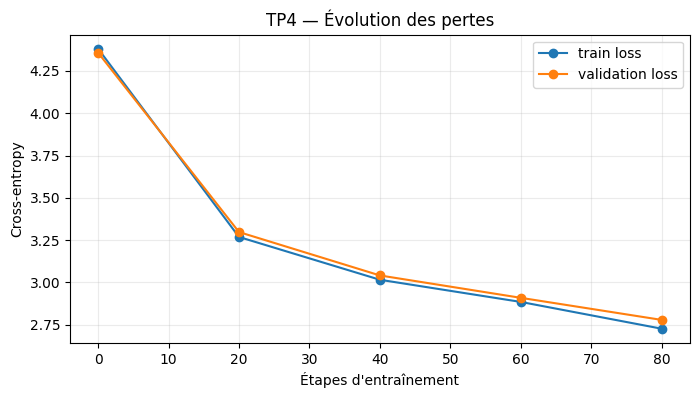

Évolution train : 4.381 → 2.727
Évolution val   : 4.357 → 2.779


In [14]:
etapes = [h["step"] for h in historique]
losses_train = [h["train"] for h in historique]
losses_val = [h["val"] for h in historique]

plt.figure(figsize=(8, 4))
plt.plot(etapes, losses_train, marker="o", label="train loss")
plt.plot(etapes, losses_val, marker="o", label="validation loss")
plt.xlabel("Étapes d'entraînement")
plt.ylabel("Cross-entropy")
plt.title("TP4 — Évolution des pertes")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Évolution train :", round(losses_train[0], 3), "→", round(losses_train[-1], 3))
print("Évolution val   :", round(losses_val[0], 3), "→", round(losses_val[-1], 3))

**Questions d'interprétation — Étapes 7–8**

- **`model.eval()` puis `model.train()` :** durant l'estimation de la loss, il faut désactiver le comportement d'entraînement de certaines couches (notamment dropout). Puis on restaure l'état précédent pour poursuivre l'optimisation.
- **Si train baisse et validation remonte :** c'est un signe possible de **sur-apprentissage**. Il faut comparer les courbes et, si nécessaire, utiliser une régularisation ou réduire les itérations.
- **Ce qu'on attend :** en entraînement complet, les deux losses devraient globalement diminuer. Les valeurs exactes dépendent de l'exécution

## Étape 9 — Générer et comparer avant/après

In [15]:
model.eval()
torch.manual_seed(2026)
texte_apres = decode(model.generate(context, max_new_tokens=2000)[0].tolist())
print("=== AVANT ENTRAÎNEMENT (250 caractères) ===")
print(texte_avant)
print("\n=== APRÈS ENTRAÎNEMENT (2000 caractères) ===")
print(texte_apres)
print("\nNombre de caractères générés après entraînement :", len(texte_apres))

=== AVANT ENTRAÎNEMENT (250 caractères) ===

K
jHv;
, Y-AbkFnLvrR!NSs
k-V3FML,'mUvTxyBwFdwLddYEcggLl!?WZLBT-QpRAvMaIWgwIkpR,yoL$fpp;Yj,iWcjUTcEt!hddzk3tLSDgqzXLLS,i!xGmPzXPA!'dt.CJSQIZkWGAVsI$KXiID3fhqLbASxzPN3qE!AuPznxtLp FHy?Qb!Wc'WB3WXvnsuTWX:FD3Scm'cCjdd!hRiQGHd:o IX3 i!
fSomtpxo!Z.TcP3Vzml

=== APRÈS ENTRAÎNEMENT (2000 caractères) ===

L
biv;
N nurour persor s
BN.

T b'nUvThy wFdwidds cggal!t:Z B
-tpResMac gwef foyongf p; j,

H
UN myohid kNtof geriliSoireGm,r thend ul sthaf G tse toongerg,

An tot wE!yunt ptro w
y p,
Wctommesond fre:
Dd ce'staddtheiin d o me yo heromttxobis chedomln be alis p, d t fWunengthare,
A y?d.inV,
M manthuve be bXno rer,

G t png ba wf
ter I, meis t Fh,
MabttiCueddchao wiriath$,
? be ic hakrs beEss Id g tdicEanourondimocofrr tet ftrt,
, w,LdOes watorlitheNHiz mlpif n y! d yve sereraRdiam:
Seku y wane pe mslien av stoLoti n p Rytpeovgthr seman wEoeliu
Ristend mI'll baf d ld thisorh tr surmrancinou do$mgiridQtf TG mmo lez s
!live iSw
AthYedeurgr he.
3 ' ton 

### Interprétation à compléter après exécution

**Avant entraînement :** les poids étant aléatoires, on obtient généralement une suite de caractères peu structurée.

**Après entraînement :** on attend des régularités de ponctuation, des espaces, des débuts de répliques et parfois des mots ou fragments ressemblant à Shakespeare. Ce petit modèle **n'est pas censé produire un anglais impeccable**.



## Expériences contrôlées — contexte, têtes et dropout

Le sujet propose de tester `block_size=16/64`, puis `1/4 têtes` à embedding constant, et d'augmenter `dropout` en cas de sur-apprentissage. La fonction suivante permet de réaliser ces **mini-expériences sans remplacer le modèle principal**. Chacune part de poids aléatoires et utilise le même nombre de pas ; ce sont des **comparaisons exploratoires**, pas des résultats finaux à 5 000 étapes.

In [16]:
def experimenter_variante(*, contexte=32, tetes=4, drop=0.0, pas=60):
    """Entraîne un modèle neuf pour comparer rapidement des configurations."""
    assert n_embd % tetes == 0
    reseau = BigramLanguageModel(context_size=contexte, num_heads=tetes,
                                n_blocks=n_layer, drop=drop).to(device)
    optim = torch.optim.AdamW(reseau.parameters(), lr=learning_rate)
    debut = estimate_loss(reseau, n_batches=5)["val"]
    for _ in range(pas):
        X, Y = get_batch("train", context_size=contexte)
        _, l = reseau(X, Y)
        optim.zero_grad(set_to_none=True)
        l.backward()
        optim.step()
    fin = estimate_loss(reseau, n_batches=5)["val"]
    return {"T": contexte, "tetes": tetes, "dropout": drop,
            "parametres": sum(p.numel() for p in reseau.parameters()),
            "val_avant": round(debut, 3), "val_apres": round(fin, 3)}

# Les variantes reprennent les suggestions des pages 29.
# Leur entraînement est indépendant de celui du modèle principal.
variantes = [(16, 4, 0.0), (64, 4, 0.0), (32, 1, 0.0), (32, 4, 0.2)]
resultats_variantes = []
for i, (contexte, tetes, drop) in enumerate(variantes):
    torch.manual_seed(1337 + i)
    resultat = experimenter_variante(contexte=contexte, tetes=tetes, drop=drop)
    resultats_variantes.append(resultat)
    print(resultat)

{'T': 16, 'tetes': 4, 'dropout': 0.0, 'parametres': 208705, 'val_avant': 4.358, 'val_apres': 2.795}
{'T': 64, 'tetes': 4, 'dropout': 0.0, 'parametres': 211777, 'val_avant': 4.343, 'val_apres': 2.809}
{'T': 32, 'tetes': 1, 'dropout': 0.0, 'parametres': 209729, 'val_avant': 4.33, 'val_apres': 2.943}
{'T': 32, 'tetes': 4, 'dropout': 0.2, 'parametres': 209729, 'val_avant': 4.415, 'val_apres': 2.849}


**Comment analyser ces expériences ?**

- **Contexte 16 → 64 :** un contexte plus long donne accès à davantage de caractères antérieurs, mais coûte plus cher dans les calculs d'attention.
- **1 tête → 4 têtes :** à `n_embd=64` constant, chaque tête est respectivement de dimension 64 ou 16. Plusieurs têtes permettent d'apprendre des mécanismes distincts de pondération.
- **Dropout 0 → 0.2 :** régularise l'entraînement, ce qui peut aider si les pertes de train et de validation s'écartent ; ce n'est pas garanti.
- **Prudence :** quelques dizaines d'étapes et un échantillonnage aléatoire ne suffisent pas pour décider scientifiquement qu'une variante est meilleure. Pour conclure, répéter avec plusieurs graines et un budget d'entraînement identique.

## Bilan des quatre TP avec réponses aux questions finales

| Classe ou composant | Notion du cours | Rôle |
|---|---|---|
| `BigramLanguageModel` du **TP1** | Modèle bigramme | Prédit le prochain caractère à partir du caractère courant uniquement. |
| `Head` et `MultiHeadAttention` | **TP2 : auto-attention causale** | Créent un contexte : chaque token peut consulter les positions présentes et passées. |
| `nn.LayerNorm` | **TP3 : normalisation** | Stabilise les features de chaque token, sans mélanger les positions. |
| `FeedForward` | **TP3 : MLP** | Transforme séparément chaque token, avec une non-linéarité. |
| `Block` | **TP4 : blocs et résidus** | Combine communication contextuelle, transformations individuelles et additions résiduelles. |
| `lm_head` | **TP4 : unembedding** | Produit les **logits** sur les caractères possibles. |
| `F.cross_entropy` + `loss.backward()` | **TP4 : apprentissage** | Compare les logits aux cibles puis propage les gradients dans **tout le modèle**. |

**Questions essentielles :**

- **Quelle brique crée le contexte ?** L'**attention masquée**, via les poids $\operatorname{softmax}(QK^\top/\sqrt{d_h})$.
- **Laquelle transforme un token ?** Le **MLP** (*feed-forward*), position par position.
- **Laquelle produit les logits ?** `lm_head`, une projection de 64 dimensions vers `vocab_size` scores.
- **Où agit la loss ?** La loss est calculée sur les positions $(B\times T)$ et sa rétropropagation ajuste les embeddings, les projections d'attention, les couches de normalisation, les MLP et `lm_head`.

